[Chapter 10](10_Forecasting_AR_MA.ipynb) built the two basic models of serial dependence: the **autoregressive (AR)** model, which regresses a series on its own past values, and the **moving-average (MA)** model, which writes it as a weighted sum of recent shocks. Each one leaves a signature in the correlograms: the PACF of an AR($p$) cuts off after lag $p$, and the ACF of an MA($q$) cuts off after lag $q$.

Many series show neither signature: both correlograms tail off. A pure AR or a pure MA model of such data needs many coefficients. This chapter combines the two parts into the **autoregressive moving-average (ARMA)** model, which describes the same dependence with far fewer. We then go through the three stages of building one on real data, 66 years of monthly temperatures: identification, estimation and evaluation.

# Learning objectives

By the end of this lecture you should be able to

1. write down an **ARMA($p, q$)** model, state when it is stationary and invertible, and pass it to `statsmodels`;
2. explain why **both** the ACF and the PACF of an ARMA process tail off, and why that makes the orders hard to read off the correlograms;
3. carry out the three stages of ARMA modelling: **identification** (stationarity, seasonality, candidate orders), **estimation**, and **evaluation**;
4. check the residuals of a fitted model with plots (ACF, histogram, QQ plot) and tests (Ljung-Box, Durbin-Watson, Jarque-Bera, Shapiro-Wilk, heteroskedasticity), and say what each failure means for the forecasts;
5. compare candidate models with AIC and BIC, forecast with an ARMA model and put the seasonality back.

# Setup

Modules and functions used in this lecture.

| Module | Used for |
|---|---|
| `numpy` | `random.default_rng`, `polyfit` |
| `pandas` | `read_csv`, `to_datetime`, `resample`, `groupby`, `diff`, `rolling` |
| `matplotlib.pyplot` | `subplots`, `plot`, `bar`, `hist`, `fill_between` |
| `seaborn` | `violinplot` |
| `scipy.stats` | `norm`, `jarque_bera`, `shapiro`, `skew`, `kurtosis` |
| `scipy.fft` | `fft`, inside the `fft_analysis` helper of Chapter 2 |
| `statsmodels.tsa.arima_process` | `ArmaProcess` -- simulate ARMA processes, their theoretical ACF/PACF, and their AR($\infty$) and MA($\infty$) weights |
| `statsmodels.tsa.stattools` | `adfuller`, `acf` |
| `statsmodels.tsa.seasonal` | `seasonal_decompose`, `STL` (Chapter 2) |
| `statsmodels.graphics.tsaplots` | `plot_acf`, `plot_pacf`, **`month_plot`** -- the seasonal subseries plot of Chapter 3 |
| `statsmodels.graphics.gofplots` | **`qqplot`** |
| `statsmodels.stats.diagnostic` | `acorr_ljungbox` (Chapter 7) |
| `statsmodels.stats.stattools` | **`durbin_watson`** |
| `statsmodels.tsa.arima.model` | **`ARIMA`** -- with `order=(p, 0, q)`, an ARMA($p, q$) model |

In [1]:
import warnings
from itertools import product

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.fft import fft

from statsmodels.tsa.arima_process import ArmaProcess
from statsmodels.tsa.stattools import adfuller, acf
from statsmodels.tsa.seasonal import seasonal_decompose, STL
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf, month_plot
from statsmodels.graphics.gofplots import qqplot
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.stats.stattools import durbin_watson
from statsmodels.tsa.arima.model import ARIMA

# Expected noise we do not want in the output:
#  - ARIMA warns when its optimizer stops before full convergence, and when it
#    replaces unusable starting values by zeros;
#  - statsmodels 0.15 announces a future change to the return type of adfuller;
#  - adfuller warns that its regression is rank-deficient on a perfect sinusoid.
from statsmodels.tools.sm_exceptions import ConvergenceWarning, EstimationWarning, SingularMatrixWarning
warnings.simplefilter("ignore", ConvergenceWarning)
warnings.simplefilter("ignore", EstimationWarning)
warnings.simplefilter("ignore", FutureWarning)
warnings.simplefilter("ignore", SingularMatrixWarning)

rng = np.random.default_rng(8990)     # reproducibility

Self-defined functions carried over from earlier chapters: the run-sequence plot (Chapter 4), the MSE (Chapter 6), the FFT period finder (Chapter 2), the two correlogram helpers of Chapter 9, and `score_table` from Chapter 10.

In [2]:
def run_sequence_plot(y, x=None, title="", xlabel="time", ylabel="value",
                      ax=None, figsize=(9, 3), color="blue", **kwargs):
    "Plot a series against time and return the axes."
    if ax is None:
        _, ax = plt.subplots(figsize=figsize)
    if x is None:
        x = getattr(y, "index", np.arange(len(y)))
    ax.plot(x, y, color=color, lw=1, **kwargs)
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
    ax.grid(alpha=0.3)
    return ax


def mse(observations, estimates):
    "Mean squared error between two equal-length sequences."
    observations = np.asarray(observations, dtype=float)
    estimates = np.asarray(estimates, dtype=float)
    if observations.shape != estimates.shape:
        raise ValueError(f"shape mismatch: {observations.shape} vs {estimates.shape}")
    return np.mean((observations - estimates) ** 2)


def fft_analysis(signal):
    "Dominant period of a signal, after removing a linear trend (Chapter 2)."
    # Linear detrending
    slope, intercept = np.polyfit(np.arange(len(signal)), signal, 1)
    trend = np.arange(len(signal)) * slope + intercept
    detrended = signal - trend

    fft_values = fft(detrended)
    frequencies = np.fft.fftfreq(len(fft_values))

    # Remove negative frequencies
    positive_frequencies = frequencies[frequencies > 0]
    magnitudes = np.abs(fft_values)[frequencies > 0]

    # Identify dominant frequency, and convert it to a period
    dominant_frequency = positive_frequencies[np.argmax(magnitudes)]
    print(f"Dominant Frequency: {dominant_frequency:.3f}")
    dominant_period = 1 / dominant_frequency
    print(f"Dominant Period: {dominant_period:.2f} time units")

    return dominant_period, positive_frequencies, magnitudes


def theory_marks(ax, values, label="theory"):
    "Mark theoretical correlations (lag 0, 1, 2, ...) on a correlogram."
    ax.plot(np.arange(len(values)), values, "_", color="red", ms=14, mew=2, label=label)
    ax.legend(loc="upper right", fontsize=8)


def correlograms(x, lags=20, process=None, title=""):
    "ACF and PACF side by side, optionally with the theoretical values of an ArmaProcess."
    fig, axes = plt.subplots(1, 2, figsize=(12, 3))
    plot_acf(x, lags=lags, ax=axes[0], title=f"ACF {title}")
    plot_pacf(x, lags=lags, ax=axes[1], title=f"PACF {title}")
    if process is not None:
        theory_marks(axes[0], process.acf(lags + 1))
        theory_marks(axes[1], process.pacf(lags + 1))
    for ax in axes:
        ax.set_xlabel("lag k")
        ax.grid(alpha=0.3)
    fig.tight_layout()
    return axes


def score_table(test, forecasts, h_short=3):
    "Test-set MSE of several forecasts, over all steps and over the first h_short steps."
    print(f"{'':34s}{f'MSE, all {len(test)} steps':>20s}{f'MSE, first {h_short} steps':>22s}")
    for name, preds in forecasts.items():
        preds = np.asarray(preds)
        print(f"{name:34s}{mse(test, preds):20.2f}{mse(test[:h_short], preds[:h_short]):22.2f}")

Three new ones save repetition below:

- `adf_test` runs the ADF test of Chapter 5 and, optionally, plots the series with its rolling mean and standard deviation.
- `forecast_with_interval` draws a fitted model's forecast and its 95% prediction interval.
- `undo_seasonal_diff` turns a forecast of the seasonally differenced series back into a forecast of the series, as we did by hand in Chapter 10.

In [3]:
def adf_test(series, window=12, plot=True):
    "ADF test (Chapter 5); optionally plot the series with its rolling mean and std."
    stat, pvalue, _, _, crit, _ = adfuller(series, autolag="AIC")
    print(f"ADF statistic: {stat:.2f},  p-value: {pvalue:.3f},  critical values: "
          + ", ".join(f"{level}: {value:.2f}" for level, value in crit.items()))
    if plot:
        ax = run_sequence_plot(series, title=f"rolling mean and standard deviation (window = {window})",
                               figsize=(12, 3.5), label="series")
        ax.plot(series.rolling(window).mean(), color="red", lw=1.5, label="rolling mean")
        ax.plot(series.rolling(window).std(), color="black", lw=1.5, label="rolling std")
        ax.legend(loc="upper right", fontsize=8)
        return ax


def forecast_with_interval(ax, fit, steps, x, color="red", label="forecast"):
    "Draw the forecast of a fitted model and its 95% prediction interval; return the forecast."
    fc = fit.get_forecast(steps)
    ci = np.asarray(fc.conf_int(alpha=0.05))
    ax.plot(x, np.asarray(fc.predicted_mean), color=color, ls="--", lw=1.5, label=label)
    ax.fill_between(x, ci[:, 0], ci[:, 1], color=color, alpha=0.15)
    return np.asarray(fc.predicted_mean)


def undo_seasonal_diff(diff_forecast, history, L=12):
    "Undo a seasonal difference: x_{T+h} = (forecast of Delta_L x_{T+h}) + x_{T+h-L}."
    values = list(np.asarray(history, dtype=float)[-L:])     # the last observed season
    for d in np.asarray(diff_forecast, dtype=float):
        values.append(d + values[-L])                        # x_{T+h-L}: observed, or itself a forecast
    return np.array(values[L:])

# The ARMA model

The ARMA($p, q$) model adds the two models of Chapter 10 together:

$$x_t = c + \phi_1 x_{t-1} + \dots + \phi_p x_{t-p} + \varepsilon_t + \theta_1\varepsilon_{t-1} + \dots + \theta_q \varepsilon_{t-q},$$

where $c$ is a constant, $\phi_1, \dots, \phi_p$ are the AR coefficients, $\theta_1, \dots, \theta_q$ are the MA coefficients, and $\varepsilon_t$ is white noise with variance $\sigma^2$. ARMA($p$, 0) is the AR($p$) model, and ARMA(0, $q$) is the MA($q$) model. Building, checking and forecasting with these models is known as the **Box-Jenkins** approach, after George Box and Gwilym Jenkins, who systematized it in their 1970 book.

With the backshift operator $B$ of Chapter 9 ($B x_t = x_{t-1}$) the model reads

$$\underbrace{(1 - \phi_1 B - \dots - \phi_p B^p)}_{\phi(B)}\; x_t \;=\; c + \underbrace{(1 + \theta_1 B + \dots + \theta_q B^q)}_{\theta(B)}\; \varepsilon_t ,$$

and these two polynomials are exactly what `ArmaProcess` takes: `ar = [1, -phi_1, ..., -phi_p]`, with the signs flipped, and `ma = [1, theta_1, ..., theta_q]`, with the signs as they are.

Each polynomial is responsible for one property.

- **Stationarity** depends on the AR part only. All roots of $\phi(z)$ must lie outside the unit circle, as for an AR($p$) model (Chapter 9).
- **Invertibility** depends on the MA part only. All roots of $\theta(z)$ must lie outside the unit circle, as for an MA($q$) model (Chapter 10).

> **Note.** Like AR and MA models, an ARMA model describes a *stationary* series, so it must be fitted to stationary data. A common rule of thumb asks for at least 100 observations.

## Why combine AR and MA?

Because the combination is **parsimonious**: it describes with two or three coefficients what a pure AR or MA model needs many coefficients for. Take the ARMA(1,1) process

$$x_t = 0.7\,x_{t-1} + \varepsilon_t + 0.7\,\varepsilon_{t-1},$$

i.e., `ar = [1, -0.7]` and `ma = [1, 0.7]`. Like every stationary and invertible ARMA model, it can be rewritten as a pure MA($\infty$), $x_t = \sum_{j \ge 0} \psi_j \varepsilon_{t-j}$ (`arma2ma`, Chapter 10), and as a pure AR($\infty$), $x_t = \sum_{j \ge 1} \pi_j x_{t-j} + \varepsilon_t$ (`arma2ar`, which returns the AR polynomial, so its signs must be flipped).

stationary: True,  invertible: True


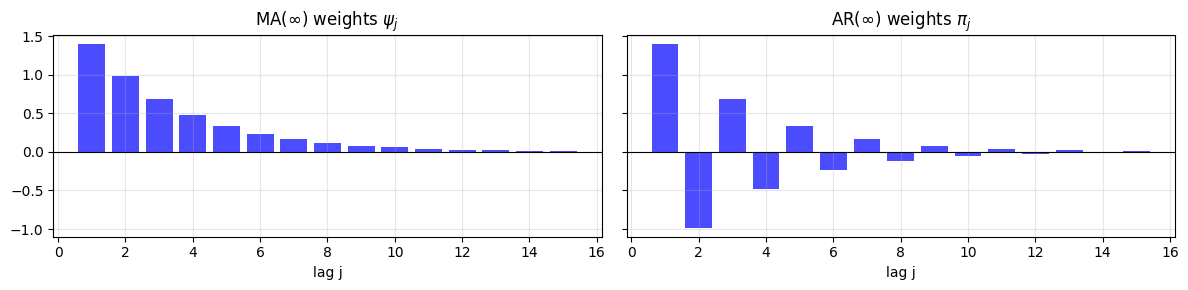

first lag with |weight| < 0.05: 11


In [4]:
arma11 = ArmaProcess(ar=np.array([1.0, -0.7]), ma=np.array([1.0, 0.7]))
print(f"stationary: {arma11.isstationary},  invertible: {arma11.isinvertible}")

J = 15
psi = arma11.arma2ma(J + 1)[1:]          # psi_1, ..., psi_J
pi = -arma11.arma2ar(J + 1)[1:]          # pi_1, ..., pi_J (sign flipped: regression coefficients)

fig, axes = plt.subplots(1, 2, figsize=(12, 3), sharey=True)
axes[0].bar(np.arange(1, J + 1), psi, color="blue", alpha=0.7)
axes[0].set(title=r"MA($\infty$) weights $\psi_j$", xlabel="lag j")
axes[1].bar(np.arange(1, J + 1), pi, color="blue", alpha=0.7)
axes[1].set(title=r"AR($\infty$) weights $\pi_j$", xlabel="lag j")
for ax in axes:
    ax.axhline(0, color="black", lw=0.8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

print("first lag with |weight| < 0.05:", np.argmax(np.abs(psi) < 0.05) + 1)

Both representations have weights $1.4 \cdot 0.7^{\,j-1}$ in absolute value, positive for the MA($\infty$), alternating in sign for the AR($\infty$). They only drop below 0.05 at lag 11. A pure MA or a pure AR model needs about ten coefficients to match what ARMA(1,1) does with two.

We simulate 250 points from this process (the `burnin` argument discards the first 1,000 simulated values, as in Chapter 9) and look at the correlograms.

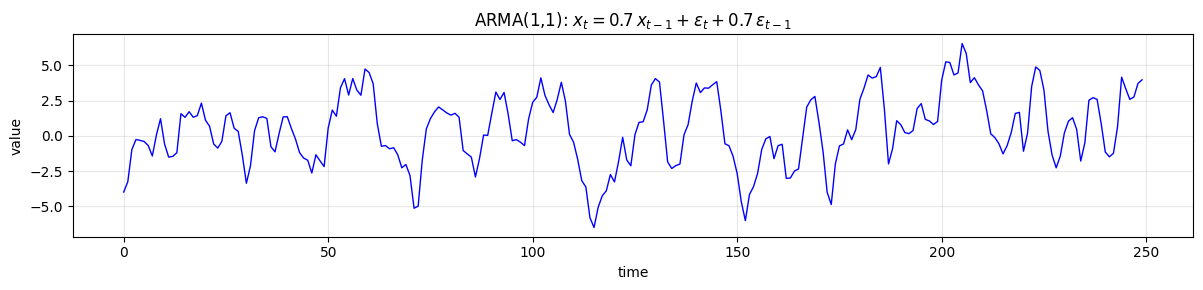

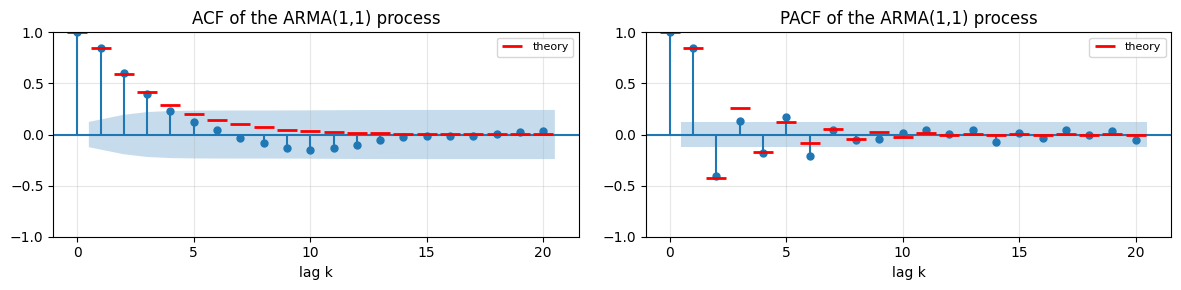

In [5]:
arma_data = arma11.generate_sample(nsample=250, scale=1, burnin=1000, distrvs=rng.standard_normal)

run_sequence_plot(arma_data, title=r"ARMA(1,1): $x_t = 0.7\,x_{t-1} + \varepsilon_t + 0.7\,\varepsilon_{t-1}$", figsize=(12, 3))
plt.tight_layout(); plt.show()

correlograms(arma_data, lags=20, process=arma11, title="of the ARMA(1,1) process")
plt.show()

Neither correlogram cuts off.

- The **ACF tails off** geometrically. After lag $q = 1$ it obeys the AR(1) recursion $\rho(k) = \phi_1\,\rho(k-1)$: from $\rho(1) \approx 0.84$ each value is 0.7 times the previous one.
- The **PACF tails off** too, with alternating signs ($0.84, -0.43, 0.26, \dots$ in theory), the pattern of an MA model with positive $\theta$.

By the rules of Chapters 9 and 10, a cut-off PACF would point to an AR model and a cut-off ACF to an MA model. Here neither happens. Let us see what happens if we fit pure AR and pure MA models anyway, and compare them with ARMA(1,1) using the **information criteria** of Chapter 8. For models fitted by maximum likelihood they read

$$\mathrm{AIC} = -2\ln\hat L + 2k, \qquad \mathrm{BIC} = -2\ln\hat L + k\ln T,$$

where $\hat L$ is the maximized likelihood, $k$ the number of estimated parameters and $T$ the number of observations. For a regression with normal errors, $-2\ln\hat L$ equals $T\ln(\mathrm{SSE}/T)$ up to a constant, which gives the formulas of Chapter 8. Lower is better, and BIC penalizes extra parameters harder.

In [6]:
rows = []
for name, order in [("AR(1)", (1, 0, 0)), ("AR(2)", (2, 0, 0)), ("AR(4)", (4, 0, 0)), ("AR(6)", (6, 0, 0)),
                    ("AR(8)", (8, 0, 0)), ("MA(1)", (0, 0, 1)), ("MA(2)", (0, 0, 2)), ("MA(4)", (0, 0, 4)),
                    ("ARMA(1,1)", (1, 0, 1))]:
    fit = ARIMA(arma_data, order=order).fit()
    rows.append({"model": name, "coefficients": order[0] + order[2], "AIC": fit.aic, "BIC": fit.bic})

pd.DataFrame(rows).set_index("model").round(1)

,coefficients,AIC,BIC
model,,,
AR(1),1,842.4,853.0
AR(2),2,792.9,807.0
AR(4),4,782.4,803.5
AR(6),6,758.3,786.4
AR(8),8,760.5,795.7
MA(1),1,899.4,910.0
MA(2),2,814.7,828.8
MA(4),4,762.6,783.7
"ARMA(1,1)",2,763.4,777.5


ARMA(1,1) has the lowest BIC, about 6 points ahead of MA(4) and 9 ahead of AR(6). By AIC, which penalizes complexity less, AR(6), AR(8) and MA(4) come out slightly better, by 1 to 5 points: with enough lags, a pure model approximates the infinite representation well. But they need four to eight coefficients for a fit that ARMA(1,1) achieves with two, and the small pure models (AR(1), AR(2), MA(1), MA(2)) are far behind.

## ARMA model identification

The correlograms of an ARMA($p, q$) process combine the behaviour of its two parts:

| Model | ACF | PACF |
|---|---|---|
| AR($p$) | tails off | **cuts off** after lag $p$ |
| MA($q$) | **cuts off** after lag $q$ | tails off |
| ARMA($p, q$) | tails off (as an AR, after lag $q$) | tails off (as an MA, after lag $p$) |

When both correlograms tail off, they tell us to use a **mixed** model, but they do not tell us the orders. In practice we read a few **candidate** orders off the correlograms, fit them all, and compare them with information criteria and residual checks. The rest of the chapter does exactly this on real data.

> **Attention.** If $\phi(B)$ and $\theta(B)$ share a factor, it cancels. For example, $(1 - 0.5B)\,x_t = (1 - 0.5B)\,\varepsilon_t$ is just white noise, $x_t = \varepsilon_t$: an "ARMA(1,1)" with $\phi_1 = 0.5$ and $\theta_1 = -0.5$ has the ACF of white noise (see the cell below). If a fitted ARMA model has an AR root and an MA root that nearly coincide, the model is **over-parameterized**: the two factors almost cancel, and their estimates are unstable. A smaller model then does the same job.

In [7]:
redundant = ArmaProcess(ar=np.array([1.0, -0.5]), ma=np.array([1.0, -0.5]))
print("theoretical ACF of (1 - 0.5B) x_t = (1 - 0.5B) e_t:", redundant.acf(6).round(3))

theoretical ACF of (1 - 0.5B) x_t = (1 - 0.5B) e_t: [1. 0. 0. 0. 0. 0.]


---

# Example data: monthly temperatures

We now model the monthly average temperatures from January 1907 to December 1972, 792 months in degrees Fahrenheit. The file is `data/arima_temp.csv`. It ends with a blank line and a title line, which `skipfooter=2` drops.

In [8]:
temp = pd.read_csv("data/arima_temp.csv", skipfooter=2, header=0, index_col=0,
                   names=["month", "temp"], engine="python")
temp.index = pd.to_datetime(temp.index)
temp = temp["temp"].asfreq("MS")        # a Series with a monthly (month-start) frequency

temp.head()

month
1907-01-01    33.3
1907-02-01    46.0
1907-03-01    43.0
1907-04-01    55.0
1907-05-01    51.8
Freq: MS, Name: temp, dtype: float64

In [9]:
temp.describe().round(2)

count    792.00
mean      53.55
std       15.82
min       11.20
25%       39.68
50%       52.15
75%       67.20
max       82.40
Name: temp, dtype: float64

The run-sequence plot, with the annual mean on top.

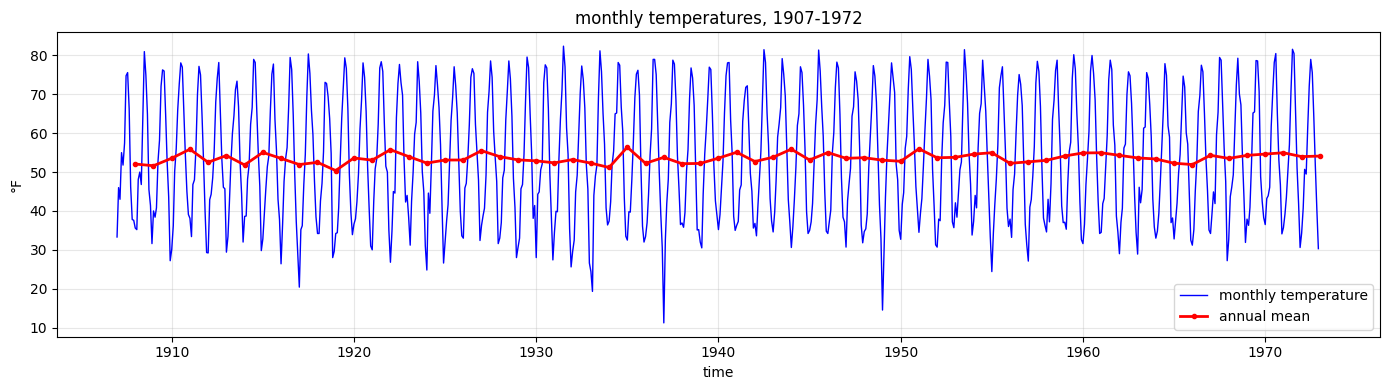

annual means between 50.4 and 56.4 °F


In [10]:
annual_temp = temp.resample("YE").mean()

ax = run_sequence_plot(temp, title="monthly temperatures, 1907-1972", ylabel="°F", figsize=(14, 4),
                       label="monthly temperature")
ax.plot(annual_temp.index, annual_temp, color="red", lw=2, marker="o", ms=3, label="annual mean")
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

print(f"annual means between {annual_temp.min():.1f} and {annual_temp.max():.1f} °F")

The annual mean stays within a band of about 6 °F, with no visible trend. We get more information about the trend and the seasonality from a seasonal decomposition (Chapter 2), here both the classical `seasonal_decompose` and `STL`.

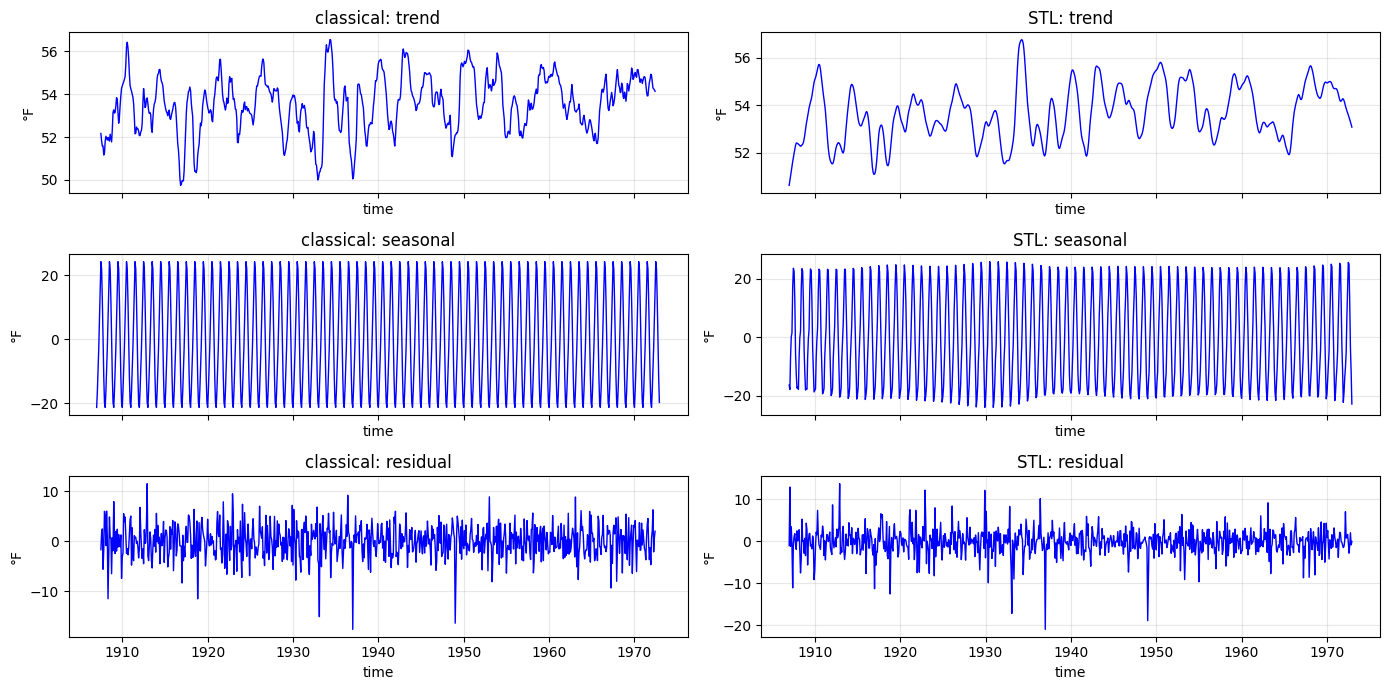

In [11]:
classical = seasonal_decompose(temp, model="additive", period=12)
stl = STL(temp, period=12, seasonal=13, robust=True).fit()

fig, axes = plt.subplots(3, 2, figsize=(14, 7), sharex=True)
for col, (name, dec) in enumerate([("classical", classical), ("STL", stl)]):
    for row, (part, values) in enumerate([("trend", dec.trend), ("seasonal", dec.seasonal),
                                          ("residual", dec.resid)]):
        run_sequence_plot(values, title=f"{name}: {part}", ylabel="°F", ax=axes[row, col])
plt.tight_layout(); plt.show()

- The **seasonality** is strong and well defined: from about $-21$ °F in January to $+24$ °F in July around the mean, with the same shape every year.
- The **trend** wanders between about 50 and 56 °F but has no direction; we can treat it as almost constant.
- The **residuals** look like noise, with a few large negative spikes: unusually cold months.

---

# The three stages of ARMA modelling

Building an ARMA model takes three stages, possibly repeated:

1. **Model identification**: choose the orders $p$ and $q$.
2. **Model estimation**: estimate the coefficients $\phi_1, \dots, \phi_p$ and $\theta_1, \dots, \theta_q$.
3. **Model evaluation**: check that the model captured the dependence in the data, i.e., that the residuals look like white noise. If they do not, go back to stage 1.

Only then do we use the model to forecast.

## Stage 1: model identification

Before choosing $p$ and $q$ we need to know two things: whether the series is stationary, and whether it has a seasonal component. Both must be dealt with first.

### Is the series stationary?

We use the tools of Chapter 5: the ADF test, and the rolling mean and standard deviation.

> **Attention.** Before we start, consider the result below.

In [12]:
sinusoid = np.sin(np.arange(200))
_, pvalue, _, _, _, _ = adfuller(sinusoid)
print(f"ADF p-value of a pure sinusoid: {pvalue:.3f}")

ADF p-value of a pure sinusoid: 0.000


The ADF test "says" that a sinusoid is stationary. It is not: its mean at time $t$ is $\sin(t)$ itself, a function of time. The test is not wrong; it answers a narrower question. The ADF test looks for a **unit root**, a feature that gives shocks a *permanent* effect and makes the level of the series drift. A sinusoid has no unit root: it is **mean-reverting**, returning to zero after every peak. So the ADF test correctly rejects the unit root.

**Rejecting a unit root is not the same as being stationary.** A periodic component makes the mean and the variance change *within* each cycle, while they stay constant *across* cycles. The ADF test cannot see that.

With this in mind we test the temperatures and their annual means.

ADF statistic: -6.48,  p-value: 0.000,  critical values: 1%: -3.44, 5%: -2.87, 10%: -2.57


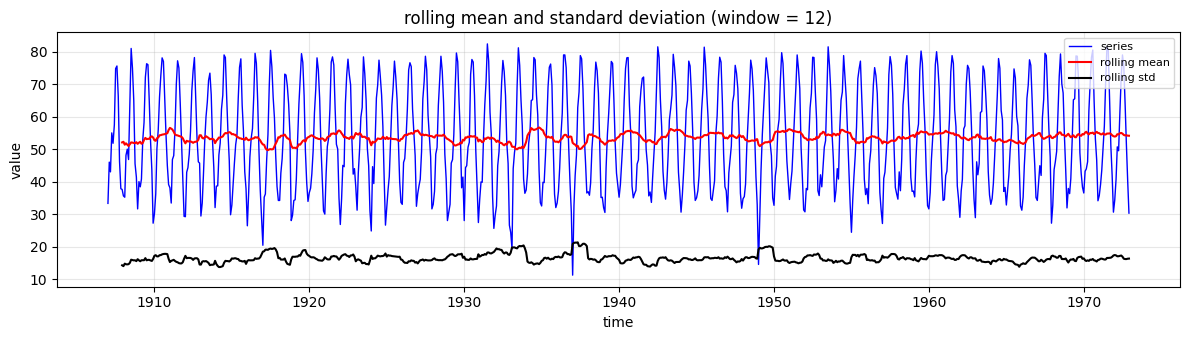

annual means:
ADF statistic: -7.88,  p-value: 0.000,  critical values: 1%: -3.54, 5%: -2.91, 10%: -2.59


In [13]:
adf_test(temp)
plt.tight_layout(); plt.show()

print("annual means:")
adf_test(annual_temp, plot=False)

Both $p$-values are essentially zero, and both series pass the ADF test, even though the monthly series obviously has a periodic component. The rolling mean and standard deviation over 12 months are roughly constant along the series, because a 12-month window always contains one full cycle. Within each year, however, the mean changes by about 40 °F. The ADF result is the sinusoid lesson again: no unit root, but still not stationary.

### Is there seasonality?

We already know three tools for detecting seasonality:

- the **ACF** (Chapter 3), which has spikes at multiples of the seasonal period;
- the **seasonal subseries plot** (Chapter 3), which `statsmodels` calls `month_plot` for monthly data;
- the **Fourier transform** (Chapter 2), which gives the period as a number.

First, here is what they look like on synthetic data with a known seasonality.

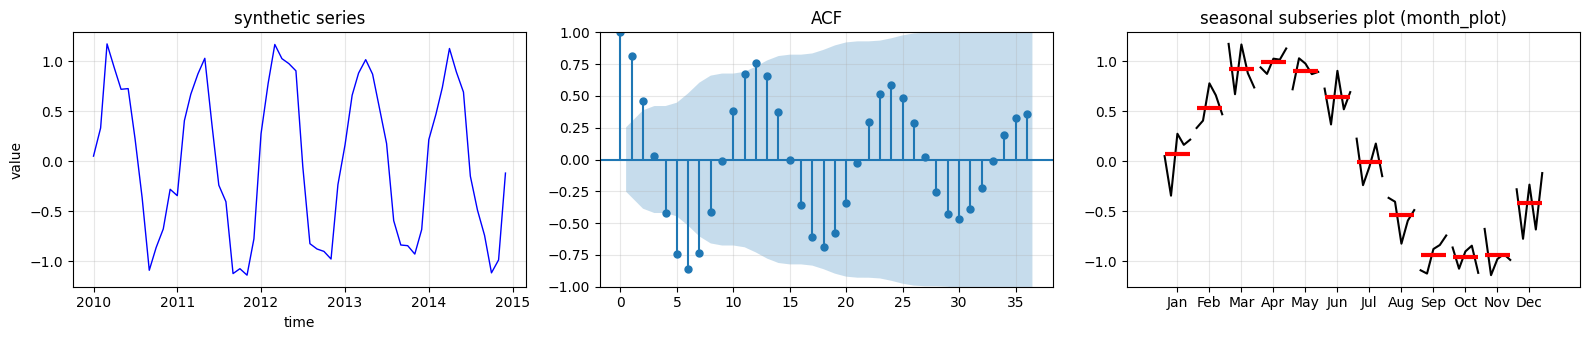

In [14]:
seas = 12            # change this and see how the plots change
dates = pd.date_range(start="2010-01-01", periods=60, freq="MS")     # 5 years of monthly data
series = pd.Series(np.sin(np.arange(60) * 2 * np.pi / seas) + rng.normal(0, 0.2, 60), index=dates)

fig, axes = plt.subplots(1, 3, figsize=(16, 3.5))
run_sequence_plot(series, title="synthetic series", ax=axes[0])
plot_acf(series, lags=36, ax=axes[1], title="ACF")
month_plot(series, ax=axes[2])
axes[2].set_title("seasonal subseries plot (month_plot)")
for ax in axes[1:]:
    ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

The ACF oscillates with period 12, positive at lags 12, 24, 36 and negative in between. In the subseries plot, each month's values (one per year) sit around a common mean (the horizontal bar), and the means trace the seasonal pattern.

> **Try it yourself**
>
> Change `seas` to 6 or 4 and rerun the cell. How do the ACF and the subseries plot change? What happens to the subseries plot if the period is not a divisor of 12?

Now the real data. Next to the `month_plot` we draw a **violin plot** of the temperature by month, which shows the same information as a distribution per month.

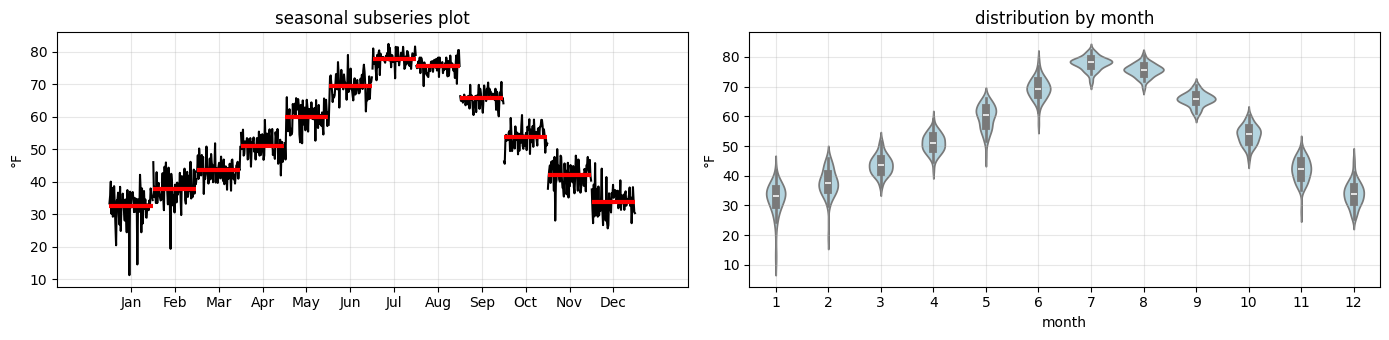

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.5))
month_plot(temp, ax=axes[0])
axes[0].set(title="seasonal subseries plot", ylabel="°F")
sns.violinplot(x=temp.index.month, y=temp.to_numpy(), ax=axes[1], color="lightblue")
axes[1].set(title="distribution by month", xlabel="month", ylabel="°F")
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

The seasonal pattern is stable: every month fluctuates around its own mean, with no month drifting up or down over the years. The violin plot shows one more thing: the **spread is not the same in every month**. Winter temperatures vary much more from year to year than summer ones. We will meet this again in the residuals.

To get the period as a number we use the `fft_analysis` function of Chapter 2.

In [16]:
dominant_period, _, _ = fft_analysis(temp.to_numpy())
print(f"Dominant period: {np.round(dominant_period)}")

Dominant Frequency: 0.083
Dominant Period: 12.00 time units
Dominant period: 12.0


### Removing the seasonality

The main seasonality is $L = 12$. We remove it with a **seasonal difference** (Chapter 5),

$$\Delta_{12}\, x_t = x_t - x_{t-12},$$

which compares every month with the same month one year earlier. The first 12 values are lost.

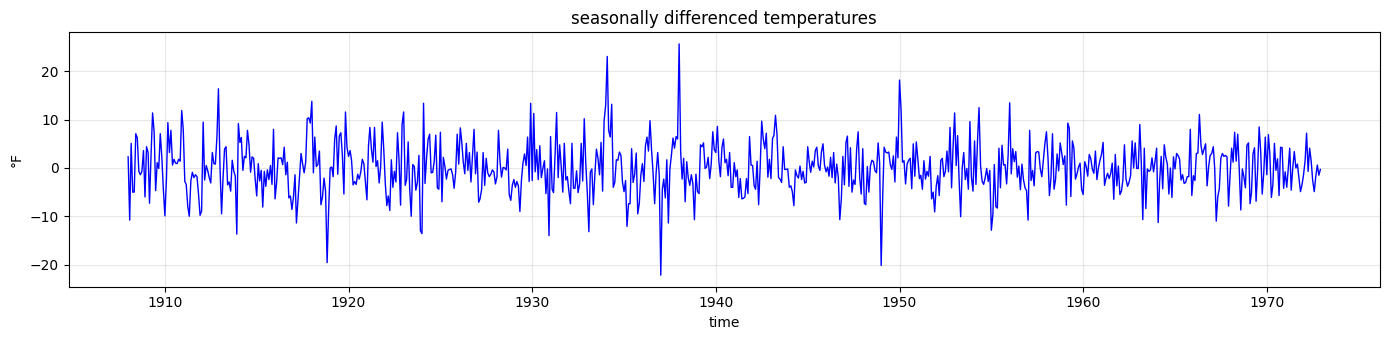

ADF statistic: -12.66,  p-value: 0.000,  critical values: 1%: -3.44, 5%: -2.87, 10%: -2.57


In [17]:
temp_d12 = temp.diff(12).iloc[12:]       # drop the 12 undefined values (slicing keeps the monthly frequency)

run_sequence_plot(temp_d12, title="seasonally differenced temperatures", ylabel="°F", figsize=(14, 3.5))
plt.tight_layout(); plt.show()
adf_test(temp_d12, plot=False)

> **Try it yourself**
>
> Redo the ACF, `month_plot` and violin plots on `temp_d12`. Is any seasonal pattern left?

### Identifying $p$ and $q$

We identify the orders as in Chapters 9 and 10.

- **AR($p$)**: draw the 95% confidence band on the PACF (`statsmodels` does it by default) and choose $p$ such that the partial autocorrelations are insignificant from lag $p + 1$ on. An AR process propagates shocks forever; its ACF decays and its PACF cuts off.
- **MA($q$)**: choose $q$ such that the ACF is insignificant from lag $q + 1$ on. An MA process forgets a shock after $q$ steps; its ACF cuts off and its PACF decays.

We look at 36 lags, three seasonal cycles.

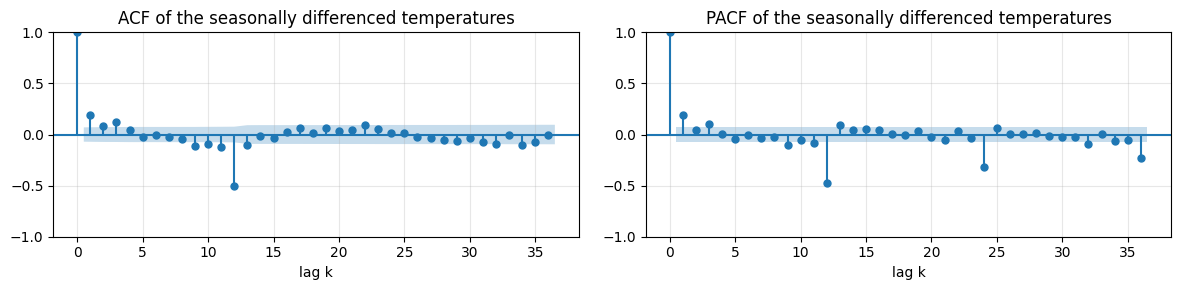

band: ±0.070;   ACF at lags 1-3: [0.19 0.08 0.12],   at lag 12: -0.50


In [18]:
correlograms(temp_d12, lags=36, title="of the seasonally differenced temperatures")
plt.show()

band = 1.96 / np.sqrt(len(temp_d12))
r = acf(temp_d12, nlags=36)
print(f"band: ±{band:.3f};   ACF at lags 1-3: {r[1:4].round(2)},   at lag 12: {r[12]:.2f}")

**Short lags.** The PACF is significant at lags 1 and 3 and small elsewhere, so $p = 1$, 2 or 3 are candidates. The ACF is significant at lags 1, 2 and 3 (0.19, 0.08, 0.12), so $q = 1$, 2 or 3 are candidates too. Both correlograms are small and neither cuts off cleanly: a mixed model with low orders is likely.

**Seasonal lags.** Both correlograms have a large negative spike at **lag 12** (about $-0.5$), with smaller ones around it. The PACF also has decaying negative spikes at 24 and 36. These come from the seasonal differencing itself, not from the short-term dynamics, so they should not count when choosing $p$ and $q$. Here is why. Write the temperature as a fixed seasonal pattern plus an anomaly, $x_t = S_t + a_t$ with $S_t = S_{t-12}$. If the anomalies are uncorrelated from one year to the next, then

$$\Delta_{12}\,x_t = a_t - a_{t-12},$$

an MA process at lag 12 with coefficient $-1$. Its ACF at lag 12 is $-1/(1 + 1) = -0.5$, exactly what we see. Seasonal differencing removes the seasonal pattern, but it **creates** a lag-12 correlation of its own. A single ACF spike at lag 12 with a decaying PACF at 12, 24, 36 is the MA signature at the seasonal lags. We will model it properly with a *seasonal* MA term in Chapter 12.

## Stage 2: model estimation

Once the orders are chosen, we estimate the AR coefficients $\phi_1, \dots, \phi_p$ and the MA coefficients $\theta_1, \dots, \theta_q$. As discussed in Chapter 10, this is a nonlinear problem, because the shocks are not observed. It is solved by **maximum likelihood** (or nonlinear least squares), and the software does it for us.

We split the data into two parts:

- a **training set**, used to estimate the coefficients;
- a **test set**, used later to evaluate the forecasts on data the model has not seen: the last 36 months, 1970 to 1972.

train: Jan 1908 - Dec 1969 (744 months),  test: Jan 1970 - Dec 1972 (36 months)


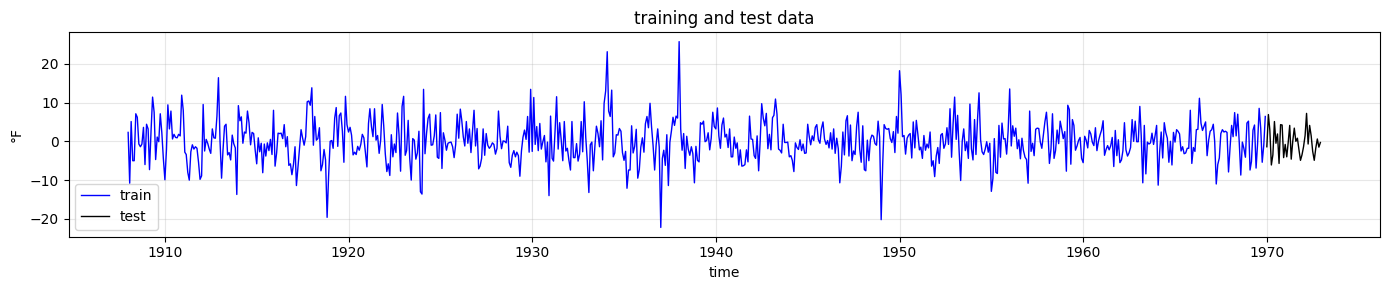

In [19]:
train = temp_d12[:"1969-12-01"]
test = temp_d12["1970-01-01":]
print(f"train: {train.index[0]:%b %Y} - {train.index[-1]:%b %Y} ({len(train)} months),  "
      f"test: {test.index[0]:%b %Y} - {test.index[-1]:%b %Y} ({len(test)} months)")

ax = run_sequence_plot(train, title="training and test data", ylabel="°F", figsize=(14, 3), label="train")
ax.plot(test, color="black", lw=1, label="test")
ax.legend(loc="lower left")
plt.tight_layout(); plt.show()

We start with the largest of the candidates, ARMA(3,3). `ARIMA` with `order=(p, 0, q)` is an ARMA($p, q$) model with a constant; the 0 in the middle means "no differencing" (Chapter 12).

In [20]:
arma33_fit = ARIMA(train, order=(3, 0, 3)).fit()
print(arma33_fit.summary())

                               SARIMAX Results                                
Dep. Variable:                   temp   No. Observations:                  744
Model:                 ARIMA(3, 0, 3)   Log Likelihood               -2248.069
Date:                Mon, 19 Oct 2026   AIC                           4512.137
Time:                        08:20:13   BIC                           4549.034
Sample:                    01-01-1908   HQIC                          4526.360
                         - 12-01-1969                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0641      0.244      0.263      0.793      -0.414       0.542
ar.L1         -0.0993      0.144     -0.692      0.489      -0.381       0.182
ar.L2         -0.8304      0.023    -35.496      0.0

The table lists, for each parameter, the estimate (`coef`), its standard error, the $z$ statistic for $H_0$: coefficient $= 0$ with its $p$-value, and a 95% confidence interval. `sigma2` is the estimated noise variance $\sigma^2$. The lower block already contains some of the residual tests we discuss below.

Three things stand out.

- Only `ar.L2` $\approx -0.83$ and `ma.L2` $\approx 1.00$ are clearly significant. The constant, `ar.L1`, `ar.L3` and `ma.L3` are not ($p > 0.05$), and `ma.L1` is borderline.
- These two significant coefficients nearly **cancel**. The AR polynomial contains roughly the factor $(1 + 0.83B^2)$, the MA polynomial roughly $(1 + 1.00B^2)$. This is the parameter redundancy of the *Attention* box above.
- `ma.L2` $\approx 1$ puts the model at the **edge of invertibility**.

The roots confirm it.

In [21]:
for name, roots in [("AR", arma33_fit.arroots), ("MA", arma33_fit.maroots)]:
    with np.errstate(divide="ignore"):                 # a positive real root has angle 0: period inf
        periods = 2 * np.pi / np.abs(np.angle(roots))
    print(f"{name} roots: modulus {np.abs(roots).round(3)},  period (months) {periods.round(1)}")

AR roots: modulus [ 1.093  1.093 21.9  ],  period (months) [3.8 3.8 inf]
MA roots: modulus [1.007 1.007 4.044],  period (months) [3.9 3.9 2. ]


A pair of complex AR roots and a pair of complex MA roots sit close together, both with a period of about 4 months (the third roots are real: `inf` is a positive and 2 a negative real root). The MA pair has modulus 1.007, practically on the unit circle. These are the signs of an over-parameterized model. Before trying another one, we look at the residuals, which tell us *what* the model is missing.

## Stage 3: model evaluation

How do we know whether a model is good enough? We look at what it could **not** explain, the residuals $e_t = x_t - \hat x_{t|t-1}$, i.e., the one-step-ahead prediction errors on the training data. If the model captured all the dependence in the data, the residuals should look like **white noise**, ideally Gaussian. Otherwise a better model exists.

We use both visual inspection and statistical tests:

- visual inspection: the residual plot, the ACF of the residuals, the histogram, the QQ plot;
- statistical tests for autocorrelation, normality and heteroskedasticity.

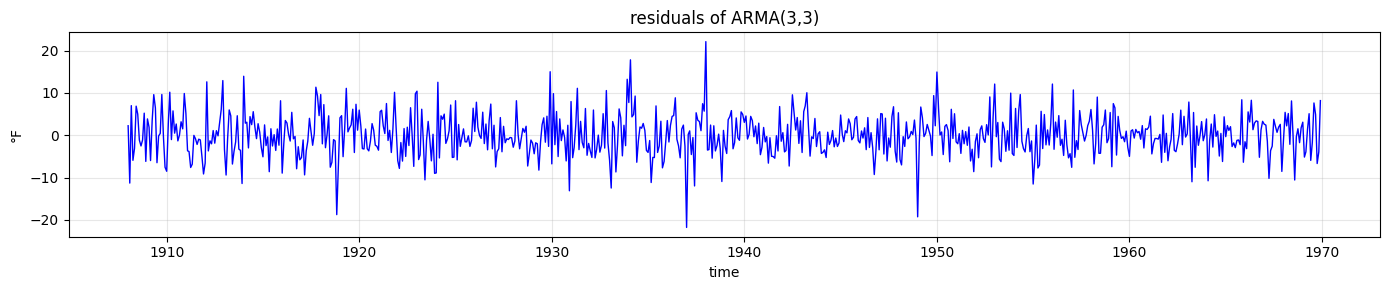

In [22]:
residuals = arma33_fit.resid

run_sequence_plot(residuals, title="residuals of ARMA(3,3)", ylabel="°F", figsize=(14, 3))
plt.tight_layout(); plt.show()

### Visual inspection

**ACF plot.** The ACF of the residuals checks for autocorrelation left in them. White noise has no significant autocorrelation at any lag. Since the data were seasonal, we look at least as far as the seasonal lags.

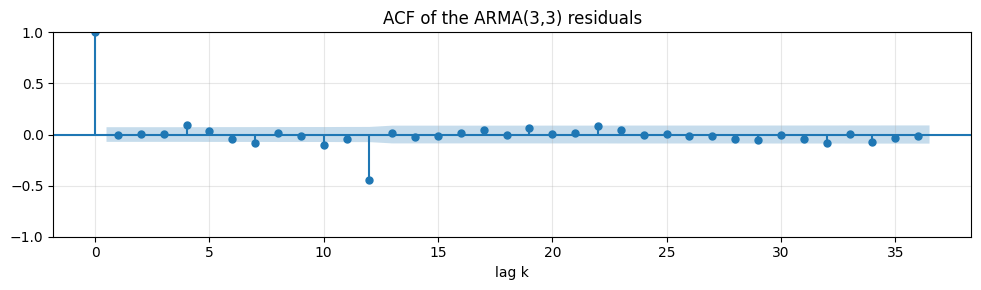

residual autocorrelation at lag 12: -0.45


In [23]:
_, ax = plt.subplots(figsize=(10, 3))
plot_acf(residuals, lags=36, ax=ax, title="ACF of the ARMA(3,3) residuals")
ax.set_xlabel("lag k"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

print(f"residual autocorrelation at lag 12: {acf(residuals, nlags=12)[12]:.2f}")

The short lags are clean, but **lag 12** has a large negative spike, $-0.45$, hardly smaller than the $-0.50$ in the data. The model did not capture the correlation created by the seasonal differencing. A check of only the first 10 lags would have missed it completely.

**Histogram and QQ plot.** These assess the normality of the residuals. The QQ plot draws the quantiles of the residuals against those of a normal distribution; normal residuals fall on the line.

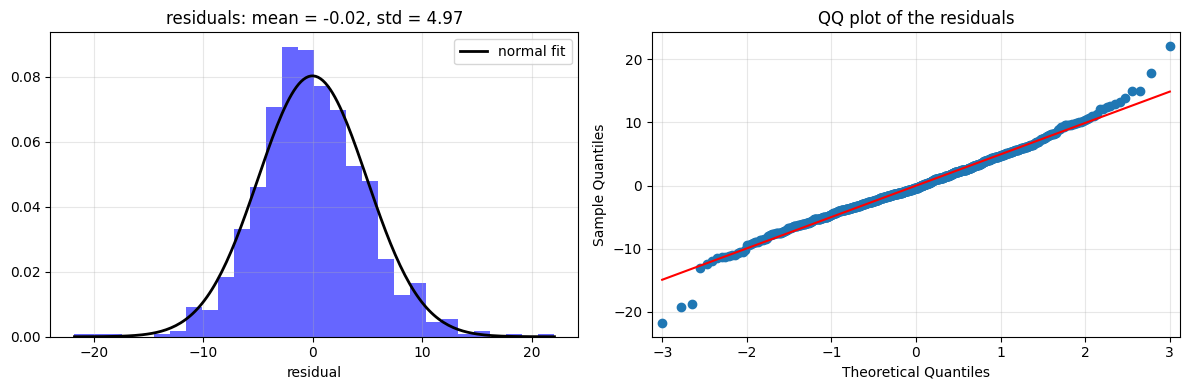

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(residuals, bins=30, density=True, color="blue", alpha=0.6)
x = np.linspace(residuals.min(), residuals.max(), 200)
axes[0].plot(x, stats.norm.pdf(x, residuals.mean(), residuals.std()), color="black", lw=2, label="normal fit")
axes[0].set(title=f"residuals: mean = {residuals.mean():.2f}, std = {residuals.std():.2f}", xlabel="residual")
axes[0].legend(); axes[0].grid(alpha=0.3)
qqplot(residuals, line="s", ax=axes[1])
axes[1].set_title("QQ plot of the residuals"); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

The histogram follows the normal curve roughly, but it is more peaked in the centre. In the QQ plot the points bend away from the line at both ends: the tails are **heavier** than those of a normal distribution.

`plot_diagnostics` draws four of these plots in one call: the standardized residuals, the histogram with a kernel density estimate, the QQ plot and the correlogram. It skips the first few residuals, which are dominated by the initialization of the model. We pass `lags=36` so that the correlogram reaches the seasonal lags (the default is 10).

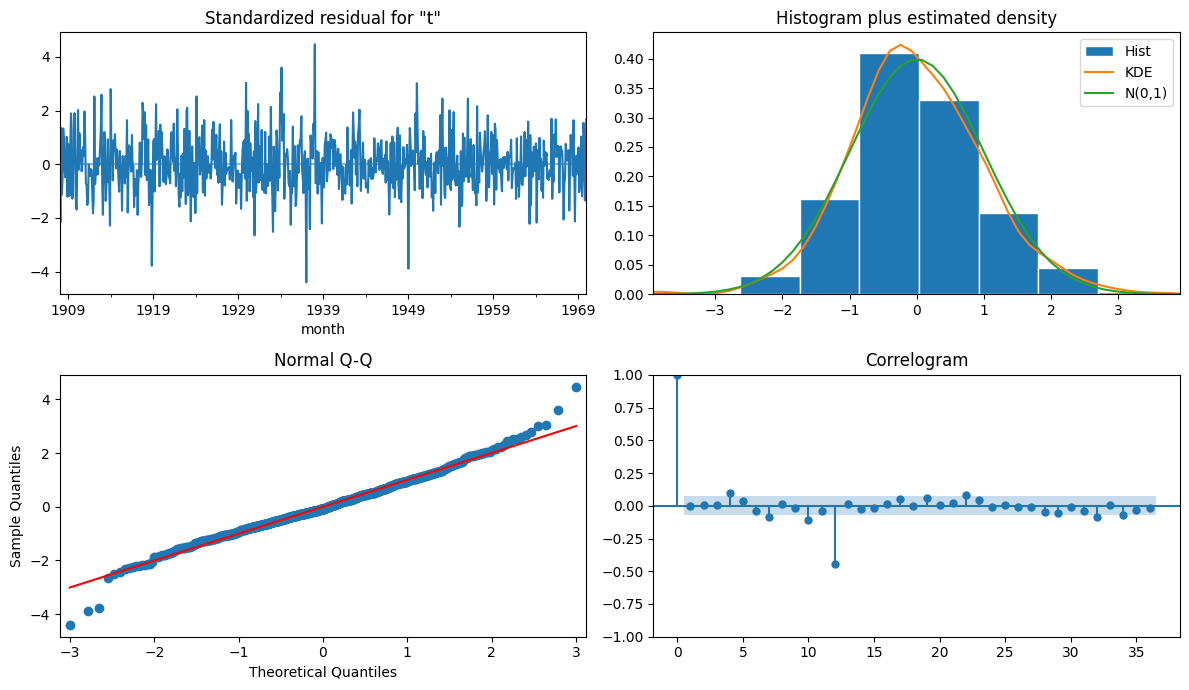

In [25]:
arma33_fit.plot_diagnostics(figsize=(12, 7), lags=36)
plt.tight_layout(); plt.show()

### Statistical tests

**Autocorrelation: the Ljung-Box test.** We used it for regression residuals in Chapter 7.

> $H_0$: the residuals are independently distributed (no autocorrelation up to lag $h$).

The statistic $Q = T(T+2)\sum_{k=1}^{h} r_k^2/(T-k)$ combines the first $h$ residual autocorrelations $r_k$. Under $H_0$ it has a $\chi^2$ distribution with $h - (p + q)$ degrees of freedom: the $p + q$ estimated coefficients have already been tuned to make the residuals look uncorrelated, which the argument `model_df` accounts for. There is a $p$-value for each $h$, and it is not always obvious which $h$ to use. For seasonal data, $h$ should cover a few seasonal cycles.

In [26]:
acorr_ljungbox(residuals, lags=[10, 24, 36], model_df=3 + 3)

,lb_stat,lb_pvalue
10,23.747588,8.973942e-05
24,188.306518,2.152924e-30
36,204.262747,7.870357e-28


All three $p$-values are essentially zero: we reject $H_0$ and conclude that **the residuals are autocorrelated**.

> **Attention.** A few shortcuts lead to the opposite conclusion. The results object has a method `test_serial_correlation("ljungbox", lags=10)` that returns the $p$-values for lags 1 to 10, without the `model_df` correction. Averaging them gives a comfortable-looking number:

In [27]:
_, pvals = arma33_fit.test_serial_correlation("ljungbox", lags=10)[0]
print(f"mean of the uncorrected Ljung-Box p-values at lags 1-10: {pvals.mean():.3f}")

mean of the uncorrected Ljung-Box p-values at lags 1-10: 0.362


> This $p$-value says "no autocorrelation" for three reasons, all of them mistakes: an average of $p$-values is not a $p$-value, the degrees of freedom are not corrected for the six estimated coefficients, and ten lags stop short of the seasonal lag 12, where the problem is.

**Autocorrelation: the Durbin-Watson test.** Its statistic

$$d = \frac{\sum_{t=2}^{T}(e_t - e_{t-1})^2}{\sum_{t=1}^{T} e_t^2} \approx 2\,(1 - r_1)$$

measures the lag-1 autocorrelation $r_1$ of the residuals. $d = 2$ means no lag-1 autocorrelation, values towards 0 positive and towards 4 negative autocorrelation. As a rule of thumb, values between 1 and 3 are acceptable.

In [28]:
print(f"Durbin-Watson: d = {durbin_watson(residuals):.2f}")

Durbin-Watson: d = 2.00


$d = 2.00$ is ideal, but Durbin-Watson only looks at **lag 1**, so it is blind to the lag-12 problem.

**Normality: the Jarque-Bera and Shapiro-Wilk tests.**

> $H_0$: the residuals are normally distributed.

Jarque-Bera compares the skewness $S$ and the kurtosis $K$ of the residuals with those of a normal distribution ($S = 0$, $K = 3$): $\mathrm{JB} = \frac{T}{6}\big(S^2 + \frac{(K-3)^2}{4}\big)$. Shapiro-Wilk measures how well the ordered residuals line up with the normal quantiles, the idea behind the QQ plot.

In [29]:
jb, jb_p, skew, kurt = arma33_fit.test_normality("jarquebera")[0]
print(f"Jarque-Bera:  p-value = {jb_p:.3f}   (skewness {skew:.2f}, kurtosis {kurt:.2f})")
print(f"Shapiro-Wilk: p-value = {stats.shapiro(residuals).pvalue:.3f}")

Jarque-Bera:  p-value = 0.000   (skewness 0.12, kurtosis 4.35)
Shapiro-Wilk: p-value = 0.000


Both tests reject $H_0$: the residuals are **not** normally distributed. The skewness is small; the problem is the kurtosis, well above the normal value of 3, i.e., the heavy tails we saw in the QQ plot.

Is the test too strict with 744 observations? For reference, here is what the same tests say about 1,000 values that really are normal.

In [30]:
normal_data = rng.standard_normal(1000)
print(f"Jarque-Bera:  p-value = {stats.jarque_bera(normal_data).pvalue:.3f}")
print(f"Shapiro-Wilk: p-value = {stats.shapiro(normal_data).pvalue:.3f}")

Jarque-Bera:  p-value = 0.211
Shapiro-Wilk: p-value = 0.279


On truly normal data neither test rejects. (Rerun the cell a few times: the $p$-values change, and about one run in twenty rejects at the 5% level, as it should.) The tests work at this sample size. Large samples do make them sensitive to *small* departures from normality, which may not matter in practice, but this one is not small, and it has a cause. Recall the violin plot: winter temperatures vary much more than summer ones. Let us look at the spread of the residuals by calendar month.

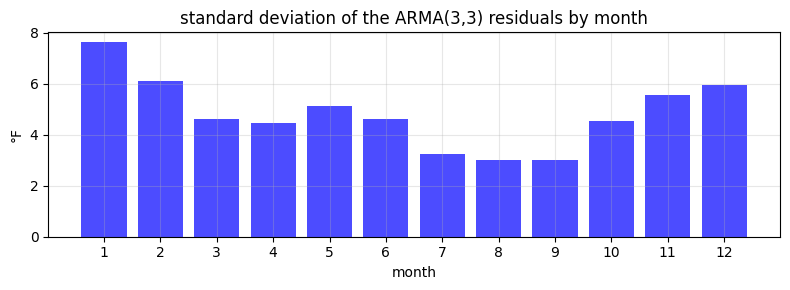

In [31]:
resid_std = residuals.groupby(residuals.index.month).std()

_, ax = plt.subplots(figsize=(8, 3))
ax.bar(resid_std.index, resid_std, color="blue", alpha=0.7)
ax.set(title="standard deviation of the ARMA(3,3) residuals by month", xlabel="month", ylabel="°F",
       xticks=range(1, 13))
ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

The residuals are about 2.5 times more variable in January (7.6 °F) than in August and September (3.0 °F). A mixture of normal distributions with different variances has heavier tails than a single normal distribution, so this **seasonal heteroskedasticity** explains the high kurtosis. The consequence: the point forecasts are not affected, but the prediction intervals, which assume one constant $\sigma^2$, are too narrow in winter and too wide in summer.

**Heteroskedasticity test.** The `breakvar` test checks whether the variance of the residuals changes along the series, by comparing the sum of squared residuals in the first third of the sample with that in the last third.

> $H_0$: no heteroskedasticity.

What $H_0$ means depends on the alternative $H_A$:

- $H_A$ increasing: $H_0$ says the variance is not increasing throughout the series;
- $H_A$ decreasing: $H_0$ says the variance is not decreasing throughout the series;
- $H_A$ two-sided (the default): $H_0$ says the variance neither increases nor decreases.

In [32]:
ratio, _ = arma33_fit.test_heteroskedasticity("breakvar", alternative="two-sided")[0]
print(f"variance ratio, last third / first third: {ratio:.2f}")
for alternative in ["increasing", "decreasing", "two-sided"]:
    _, pval = arma33_fit.test_heteroskedasticity("breakvar", alternative=alternative)[0]
    print(f"H_A: {alternative:11s}  p-value = {pval:.3f}")

variance ratio, last third / first third: 0.77
H_A: increasing   p-value = 0.980
H_A: decreasing   p-value = 0.020
H_A: two-sided    p-value = 0.039


The residual variance in the last third is about 0.77 times that of the first third. The decreasing and two-sided alternatives reject $H_0$ at the 5% level: there is mild evidence that the residuals became less variable over the decades. Note what this test can **not** see: comparing the beginning of the sample with the end tells us nothing about the winter-summer difference we just found, which repeats every year.

**Summary of the checks**

| Check | Looks at | Result | Verdict |
|---|---|---|---|
| ACF of residuals | all lags up to 36 | $-0.45$ at lag 12 | fail |
| Ljung-Box, $h$ = 10, 24, 36 | the first $h$ lags together | $p < 0.001$ | fail |
| Durbin-Watson | lag 1 only | $d = 2.00$ | pass |
| Histogram, QQ plot | shape of the distribution | heavy tails | doubtful |
| Jarque-Bera, Shapiro-Wilk | normality | $p < 0.001$ | fail |
| `breakvar` | first vs last third of the sample | two-sided $p = 0.04$ | mild fail |

The main problem is clear: the residuals still contain the **lag-12 correlation**. The non-normality comes mostly from the seasonal heteroskedasticity, which an ARMA model with constant $\sigma^2$ cannot remove; it matters for the intervals, not for the point forecasts. We go back to stage 1 and try other candidates.

### Comparing candidate models with AIC and BIC

We fit every ARMA($p, q$) with $p, q \le 3$, the candidates of stage 1, and record AIC, BIC, the residual autocorrelation at lag 12, and the Ljung-Box $p$-value at $h = 24$.

In [33]:
rows = []
for p, q in product(range(4), range(4)):
    fit = ARIMA(train, order=(p, 0, q)).fit()
    rows.append({"model": f"ARMA({p},{q})", "AIC": fit.aic, "BIC": fit.bic,
                 "min |MA root|": np.abs(fit.maroots).min() if q > 0 else np.nan,
                 "resid ACF, lag 12": acf(fit.resid, nlags=12)[12],
                 "Ljung-Box p, h = 24": acorr_ljungbox(fit.resid, lags=[24], model_df=p + q)["lb_pvalue"].iloc[0]})
candidates = pd.DataFrame(rows).set_index("model")

candidates.sort_values("AIC").round(3)

,AIC,BIC,min |MA root|,"resid ACF, lag 12","Ljung-Box p, h = 24"
model,,,,,
"ARMA(2,3)",4502.988,4535.272,1.000,-0.429,0.0
"ARMA(3,2)",4503.778,4536.062,1.000,-0.431,0.0
"ARMA(3,3)",4512.137,4549.034,1.007,-0.446,0.0
"ARMA(2,2)",4541.023,4568.695,1.000,-0.467,0.0
"ARMA(3,0)",4562.612,4585.672,NaN,-0.491,0.0
"ARMA(0,3)",4564.271,4587.331,2.027,-0.490,0.0
"ARMA(1,3)",4564.315,4591.988,2.039,-0.491,0.0
"ARMA(3,1)",4564.594,4592.266,29.338,-0.491,0.0
"ARMA(1,1)",4565.470,4583.918,2.441,-0.492,0.0


- AIC and BIC agree on the ranking at the top: ARMA(2,3), ARMA(3,2), ARMA(3,3), ARMA(2,2). All four have an MA root on the unit circle (`min |MA root|` = 1.00), the edge-of-invertibility symptom we found in ARMA(3,3). The small models, such as AR(1), AR(3) and ARMA(1,1), are about 60 AIC points behind.
- But **every** candidate leaves a residual autocorrelation between $-0.43$ and $-0.50$ at lag 12, and every Ljung-Box test rejects ($p$ rounds to 0.0).

No combination of short lags can produce a correlation at lag 12 alone. The large models improve the likelihood by bending their short-lag structure towards the seasonal lag (the period-4 roots of ARMA(3,3) are an example: 12 is a multiple of 4), but they cannot remove the correlation. What is missing is not more short lags but a term **at lag 12**: a seasonal MA term (Chapter 12). Until then we need another way to deal with the seasonality.

### A second route: subtracting the monthly means

In Chapter 10, subtracting an estimated trend and seasonality worked better than differencing. Here the trend is flat and the seasonal pattern is stable, as the subseries plot showed, so we can estimate the seasonality simply by the **monthly means** of the training years, sometimes called the *climatology*. Subtracting them leaves the **anomalies**: how much warmer or colder than usual each month was.

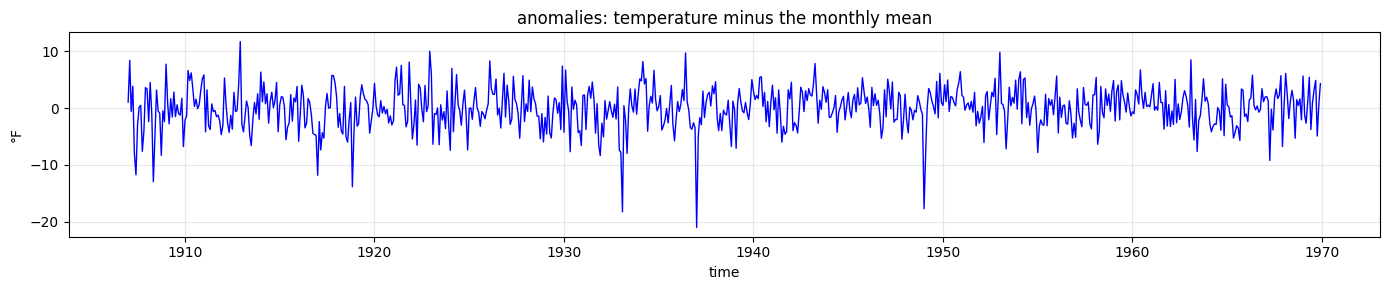

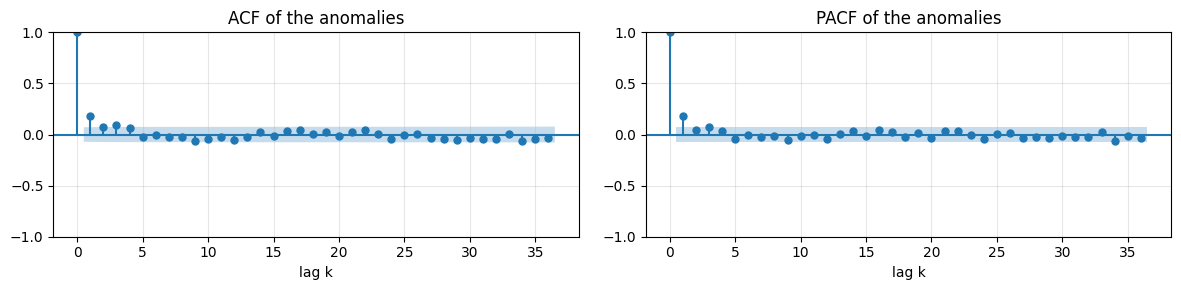

In [34]:
temp_train = temp[:"1969-12-01"]
temp_test = temp["1970-01-01":]

monthly_means = temp_train.groupby(temp_train.index.month).mean()          # one value per calendar month
anomalies = temp_train - monthly_means.loc[temp_train.index.month].to_numpy()

run_sequence_plot(anomalies, title="anomalies: temperature minus the monthly mean", ylabel="°F", figsize=(14, 3))
plt.tight_layout(); plt.show()

correlograms(anomalies, lags=36, title="of the anomalies")
plt.show()

The lag-12 spike is gone. The ACF of the anomalies is small and decays quickly (0.18, 0.07, 0.09 at lags 1-3), and the PACF has one clear spike at lag 1. This points to an AR(1), or an ARMA(1,1) to capture the slow decay after lag 1. We fit both and check them.

In [35]:
for p, q in [(1, 0), (1, 1)]:
    fit = ARIMA(anomalies, order=(p, 0, q)).fit()
    lb = acorr_ljungbox(fit.resid, lags=[12, 24, 36], model_df=p + q)["lb_pvalue"]
    print(f"ARMA({p},{q}): AIC = {fit.aic:.1f}, BIC = {fit.bic:.1f},  "
          f"Ljung-Box p (h = 12, 24, 36) = {lb.round(3).tolist()},  coefficients {fit.params.round(3).to_dict()}")
    if (p, q) == (1, 1):
        anom_fit = fit

ARMA(1,0): AIC = 4089.3, BIC = 4103.2,  Ljung-Box p (h = 12, 24, 36) = [0.297, 0.6, 0.668],  coefficients {'const': 0.001, 'ar.L1': 0.182, 'sigma2': 12.977}
ARMA(1,1): AIC = 4088.3, BIC = 4106.8,  Ljung-Box p (h = 12, 24, 36) = [0.456, 0.721, 0.814],  coefficients {'const': 0.004, 'ar.L1': 0.556, 'ma.L1': -0.393, 'sigma2': 12.926}


Both models pass the Ljung-Box test at every $h$, and they are almost indistinguishable by AIC; BIC prefers the smaller AR(1). We keep ARMA(1,1). Its residual variance is about half that of the ARMA models above. That is not a better fit to the same data: the seasonally differenced series has twice the variance of the anomalies, since $\mathrm{Var}(a_t - a_{t-12}) = 2\,\mathrm{Var}(a_t)$.

> **Note.** These AIC values are not comparable with those of the table above: the models were fitted to a different series (Chapter 8: criteria compare models of the **same** data).

## Forecasting with an ARMA model

Once the model is fitted, we use it to forecast the test period. ARMA models produce a **probabilistic** forecast: for each future time step they give a whole distribution, normal with a mean and a variance. The mean is the most likely value and is our point forecast. The rest of the distribution gives the prediction intervals. `get_forecast` returns both. We start with the seasonally differenced series and the ARMA(3,3) model.

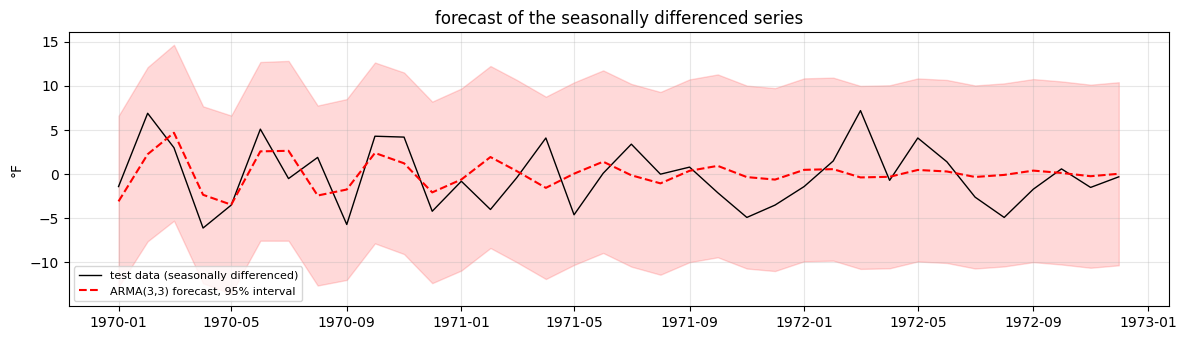

In [36]:
_, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(test.index, test, color="black", lw=1, label="test data (seasonally differenced)")
d12_forecast = forecast_with_interval(ax, arma33_fit, len(test), test.index, label="ARMA(3,3) forecast, 95% interval")
ax.set(title="forecast of the seasonally differenced series", ylabel="°F"); ax.grid(alpha=0.3)
ax.legend(loc="lower left", fontsize=8)
plt.tight_layout(); plt.show()

During the first year the forecast oscillates with the 4-month period of the near-unit roots; then it decays to the mean, about 0. The interval is wide, about ±10 °F, because the differenced series is noisy.

What we actually want is a forecast of the **temperature**. We undo the seasonal difference, $\hat x_{T+h} = \widehat{\Delta_{12} x}_{T+h} + x_{T+h-12}$, where $x_{T+h-12}$ is observed for $h \le 12$ and is itself a forecast afterwards. For the second route, the forecast is the monthly mean plus the ARMA(1,1) forecast of the anomaly. We compare both with two benchmarks: the **seasonal naive** forecast of Chapter 1, which repeats the last observed year, and the **monthly means** alone.

                                     MSE, all 36 steps    MSE, first 3 steps
seasonal naive                                   21.28                 19.52
differencing + ARMA(3,3)                          9.03                  9.08
monthly means                                     8.82                 16.64
monthly means + ARMA(1,1)                         8.57                 13.42


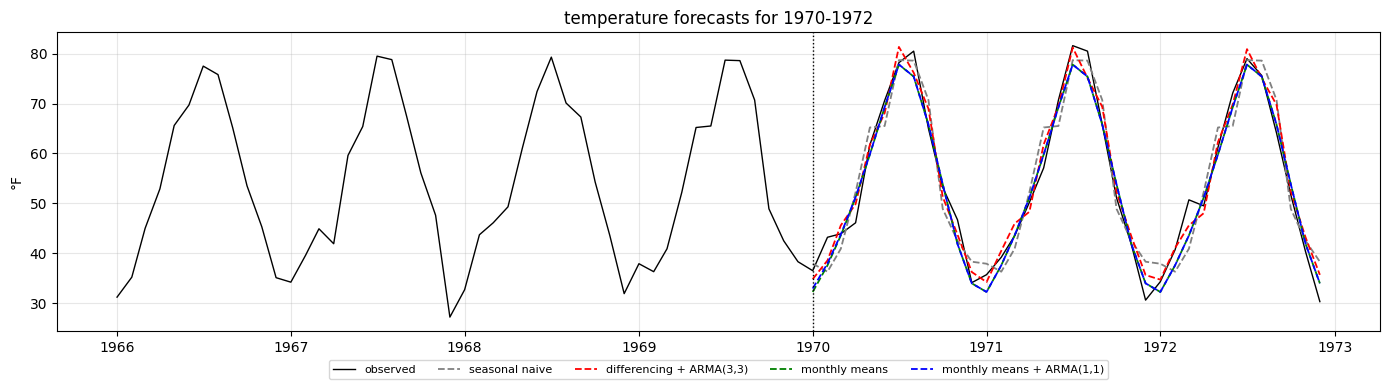

In [37]:
means_test = monthly_means.loc[temp_test.index.month].to_numpy()

forecasts = {
    "seasonal naive":                np.tile(temp_train.iloc[-12:].to_numpy(), 3),
    "differencing + ARMA(3,3)":      undo_seasonal_diff(d12_forecast, temp_train),
    "monthly means":                 means_test,
    "monthly means + ARMA(1,1)":     means_test + anom_fit.forecast(len(temp_test)).to_numpy(),
}
score_table(temp_test, forecasts)

_, ax = plt.subplots(figsize=(14, 4))
ax.plot(temp["1966-01-01":], color="black", lw=1, label="observed")
for (name, preds), color in zip(forecasts.items(), ["gray", "red", "green", "blue"]):
    ax.plot(temp_test.index, preds, ls="--", lw=1.3, color=color, label=name)
ax.axvline(temp_test.index[0], color="black", ls=":", lw=1)
ax.set(title="temperature forecasts for 1970-1972", ylabel="°F"); ax.grid(alpha=0.3)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=5, fontsize=8)
plt.tight_layout(); plt.show()

On this test period:

- The **seasonal naive** forecast is by far the worst (MSE 21.3). It copies 1969, noise included, into every following year: the lesson of Chapter 10 again.
- The **monthly means** cut the error by more than half (8.8); in the plot they are hidden behind the blue line. Adding the ARMA(1,1) anomaly forecast helps a little more (8.6), mostly in the first months.
- **Differencing + ARMA(3,3)** does almost as well as the monthly means (9.0), which is surprising for a model that failed its residual checks.

Is the ARMA(3,3) result real? Chapter 10 warned that a single test period is a noisy basis for judging a model. The seasonal naive forecast for 1970 is the 1969 temperature, so it inherits the 1969 anomalies; the ideal correction would subtract them. Compare the ARMA(3,3) forecast of the differenced series for 1970 with minus the 1969 anomalies:

In [38]:
anomalies_1969 = anomalies["1969-01-01":].to_numpy()
print(f"correlation between the ARMA(3,3) forecast for 1970 and minus the 1969 anomalies: "
      f"{np.corrcoef(d12_forecast[:12], -anomalies_1969)[0, 1]:.2f}")

correlation between the ARMA(3,3) forecast for 1970 and minus the 1969 anomalies: 0.86


The two are strongly correlated: in 1970 the oscillating forecast happened to supply most of the correction that the seasonal naive forecast needed. Was that skill or luck?

### Is one test period enough?

We repeat the comparison from many **forecast origins**: every three months from December 1940 to December 1968, we forecast the following 12 months with each method, using only the data available at the origin, and average the MSE over all origins. To keep the computation cheap we do not re-estimate the coefficients at each origin. `fit.apply(data)` runs a fitted model, with its coefficients fixed, on new data, and forecasts from the end of that data. The coefficients come from the training fit, so this is not a fully out-of-sample test of the *estimation*; but every forecast uses only data before its origin, and all methods are treated the same way.

In [39]:
origins = pd.date_range("1940-12-01", "1968-12-01", freq="3MS")
H = 12
errors = {name: [] for name in forecasts}

for origin in origins:
    past = temp[:origin]                                   # everything known at the origin
    future = temp[origin:].iloc[1:H + 1]                   # the next 12 months
    means_o = past.groupby(past.index.month).mean()        # monthly means from the past only
    means_fc = means_o.loc[future.index.month].to_numpy()
    anom_o = past - means_o.loc[past.index.month].to_numpy()

    preds = {
        "seasonal naive":            past.iloc[-12:].to_numpy(),
        "differencing + ARMA(3,3)":  undo_seasonal_diff(arma33_fit.apply(past.diff(12).iloc[12:]).forecast(H), past),
        "monthly means":             means_fc,
        "monthly means + ARMA(1,1)": means_fc + anom_fit.apply(anom_o).forecast(H).to_numpy(),
    }
    for name, pred in preds.items():
        errors[name].append(mse(future, pred))

print(f"average 12-month MSE over {len(origins)} forecast origins:")
for name, errs in errors.items():
    print(f"  {name:30s}{np.mean(errs):6.2f}")

average 12-month MSE over 113 forecast origins:
  seasonal naive                 22.12
  differencing + ARMA(3,3)       20.51
  monthly means                  11.02
  monthly means + ARMA(1,1)      10.97


Averaged over 113 origins, the picture changes.

- **Differencing + ARMA(3,3)** is barely better than the seasonal naive forecast (20.5 vs 22.1). Its success on 1970-1972 was mostly luck.
- The **monthly-means route** is twice as accurate (11.0). Over 12 months the ARMA(1,1) anomaly forecast adds almost nothing on average (10.97 vs 11.02): the anomalies have little memory (lag-1 autocorrelation 0.18), so their forecast returns to zero within a few months.

Seasonal differencing compares each month with the same month of *one* earlier year, so every forecast inherits that year's anomaly. A non-seasonal ARMA cannot undo this, because the correction it would need lies at lag 12. The monthly means average over *all* earlier years. In Chapter 12 a **seasonal** MA term makes the differencing route work, and we will see that it then becomes almost the same model as the monthly-means route.

---

# Summary

**The ARMA($p, q$) model**

$$\phi(B)\,x_t = c + \theta(B)\,\varepsilon_t,$$

passed to `ArmaProcess` as `ar = [1, -phi_1, ..., -phi_p]` and `ma = [1, theta_1, ..., theta_q]`, and fitted with `ARIMA(x, order=(p, 0, q))`.

- It is **stationary** if the roots of $\phi(z)$ lie outside the unit circle, and **invertible** if the roots of $\theta(z)$ do.
- It is **parsimonious**: an ARMA(1,1) can do the work of an AR or MA model with ten or more lags.
- Both its ACF and its PACF **tail off**, so the correlograms suggest candidate orders but do not determine them.
- Watch for **near-cancelling** AR and MA roots: they signal an over-parameterized model.

**The three stages**

1. **Identification.** Check stationarity (ADF, rolling statistics), but remember that rejecting a unit root does not prove stationarity, as the sinusoid showed. Detect seasonality (ACF, `month_plot`, FFT) and remove it, by seasonal differencing or by subtracting the monthly means. Read candidate orders off the PACF ($p$) and the ACF ($q$).
2. **Estimation.** Maximum likelihood, `ARIMA(x, order=(p, 0, q)).fit()`; read the coefficients and their significance in `summary()`.
3. **Evaluation.** The residuals should be white noise.

| Check | Tool | What it detects |
|---|---|---|
| Autocorrelation | ACF plot, **Ljung-Box** (with `model_df = p + q`) | dependence left in the residuals, at any lag up to $h$ |
| | Durbin-Watson | lag-1 autocorrelation only |
| Normality | histogram, QQ plot, Jarque-Bera, Shapiro-Wilk | skewness, heavy tails (matter for the intervals) |
| Heteroskedasticity | `breakvar` | variance changing between the start and the end of the sample |

Then compare the surviving candidates with **AIC and BIC**, fitted to the same data, and evaluate the forecasts on held-out data, preferably from **many forecast origins**.

**What we learned on the temperatures**

1. Seasonal differencing creates a lag-12 correlation of about $-0.5$, which **no non-seasonal ARMA can remove**; AIC and BIC then reward models that bend their short lags towards it.
2. One test period can flatter a model: the ARMA(3,3) looked good on 1970-1972, and was barely better than seasonal naive over 113 origins.
3. Subtracting the monthly means and modelling the anomalies with ARMA(1,1) gave clean residuals and the best forecasts.

**Next.** ARIMA puts the differencing inside the model, so that `statsmodels` does the bookkeeping of `undo_seasonal_diff` for us. SARIMA adds seasonal AR and MA terms, the missing term at lag 12.